In [12]:
import torch
from torch import nn
from src.data.dataset import MVTecDataset
from torchvision import transforms
from torch.utils.data import DataLoader
from torch.optim.lr_scheduler import ReduceLROnPlateau
import numpy as np
import matplotlib.pyplot as plt

In [13]:
ROOT_DIR = 'D:/Unsupervised-Anomaly-Detection-Using-Autoencoder-Architecture/data'
LEARNING_RATE = 1e-3
EPOCHS = 175
BATCH_SIZE = 64
LATENT_DIM = 512        # Care for overfitting, may have to be turned down
BOTTLE_MEAN = [0.5354132056236267, 0.531684160232544, 0.5479597449302673]
BOTTLE_STD = [0.3656117916107178, 0.3659615218639374, 0.34921830892562866]
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

In [14]:
train_test_transform = transforms.Compose([
    transforms.Resize((256, 256), interpolation=transforms.InterpolationMode.NEAREST),
    transforms.ToTensor(),
    transforms.Normalize(mean=BOTTLE_MEAN, std=BOTTLE_STD)
])

mask_transform = transforms.Compose([
    transforms.Resize((256, 256), interpolation=transforms.InterpolationMode.NEAREST),
    transforms.ToTensor()
])

In [15]:
train_data = MVTecDataset(root_dir=ROOT_DIR,
                        category='bottle', 
                        mode='train', 
                        transform=train_test_transform, 
                        mask_transform=None)

test_data = MVTecDataset(root_dir=ROOT_DIR, 
                        category='bottle', 
                        mode='test', 
                        transform=train_test_transform,
                        mask_transform=mask_transform)

train_dataloader = DataLoader(
    dataset=train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    pin_memory=True,
    num_workers=2
)

test_dataloader = DataLoader(
    dataset=test_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    pin_memory=True,
    num_workers=2
)

In [16]:
class BottleAutoencoder(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(
                in_channels=3,
                out_channels=32,
                kernel_size=(3, 3),
                stride=2,
                padding=1
            ),
            nn.BatchNorm2d(num_features=32),
            nn.LeakyReLU(inplace=True),

            nn.Conv2d(
                in_channels=32,
                out_channels=64,
                kernel_size=(3, 3),
                stride=2,
                padding=1,
            ),
            nn.BatchNorm2d(num_features=64),
            nn.LeakyReLU(inplace=True),

            nn.Conv2d(
                in_channels=64,
                out_channels=128,
                kernel_size=(3, 3),
                stride=2,
                padding=1
            ),
            nn.BatchNorm2d(num_features=128),
            nn.LeakyReLU(inplace=True),

            nn.Conv2d(
                in_channels=128,
                out_channels=256,
                kernel_size=(3, 3),
                stride=2,
                padding=1
            ),
            nn.BatchNorm2d(num_features=256),
            nn.LeakyReLU(inplace=True),

            nn.Conv2d(
                in_channels=256,
                out_channels=512,
                kernel_size=(3, 3),
                stride=2,
                padding=1
            ),
            nn.BatchNorm2d(num_features=512),
            nn.LeakyReLU(inplace=True),

            nn.Conv2d(
                in_channels=512,
                out_channels=64,
                kernel_size=(1, 1),
                stride=1,
                padding=0
            ),
            nn.BatchNorm2d(num_features=64),
            nn.LeakyReLU(inplace=True),

            nn.Flatten(),
            nn.Linear(64 * 8 * 8, latent_dim)
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64 * 8 * 8),
            nn.Unflatten(dim=1, unflattened_size=(64, 8, 8)),

            nn.Conv2d(
                in_channels=64,
                out_channels=512,
                kernel_size=(1, 1),
                stride=1,
                padding=0
            ),
            nn.BatchNorm2d(num_features=512),
            nn.LeakyReLU(inplace=True),

            nn.Upsample(scale_factor=2, mode='nearest'),
            nn.Conv2d(
                in_channels=512,
                out_channels=256,
                kernel_size=(3, 3),
                stride=1,
                padding=1
            ),
            nn.BatchNorm2d(num_features=256),
            nn.LeakyReLU(inplace=True),

            nn.Upsample(scale_factor=2, mode='nearest'),
            nn.Conv2d(
                in_channels=256,
                out_channels=128,
                kernel_size=(3, 3),
                stride=1, 
                padding=1
            ),
            nn.BatchNorm2d(num_features=128),
            nn.LeakyReLU(inplace=True),

            nn.Upsample(scale_factor=2, mode='nearest'),
            nn.Conv2d(
                in_channels=128,
                out_channels=64,
                kernel_size=(3, 3),
                stride=1,
                padding=1
            ),
            nn.BatchNorm2d(num_features=64),
            nn.LeakyReLU(inplace=True),

            nn.Upsample(scale_factor=2, mode='nearest'),
            nn.Conv2d(
                in_channels=64,
                out_channels=32,
                kernel_size=(3, 3),
                stride=1,
                padding=1
            ),
            nn.BatchNorm2d(num_features=32),
            nn.LeakyReLU(inplace=True),

            nn.Upsample(scale_factor=2, mode='nearest'),
            nn.Conv2d(
                in_channels=32,
                out_channels=3,
                kernel_size=(3, 3),
                stride=1,
                padding=1
            ),
        )

    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

In [17]:
model = BottleAutoencoder(latent_dim=LATENT_DIM)
model = model.to(DEVICE)
criterion = nn.L1Loss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
scheduler = ReduceLROnPlateau(
    optimizer=optimizer,
    mode='min',
    factor=0.5,
    patience=5
)

In [ ]:
model.train()
for epoch in range(EPOCHS):
    train_loss = 0.0
    for images, *_ in train_dataloader:
        images = images.to(DEVICE)
        outputs = model(images)

        loss = criterion(outputs, images)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)

    epoch_loss = train_loss / len(train_dataloader.dataset)
    scheduler.step(epoch_loss)

    print(f"Epoch [{epoch+1}/{EPOCHS}], Loss: {epoch_loss:.6f}")
    

In [18]:
torch.save(model.state_dict(), '../src/models/bottle_autoencoder.pth')

In [20]:
model.load_state_dict(torch.load('../src/models/bottle_autoencoder.pth', map_location=DEVICE))

<All keys matched successfully>

In [21]:
model.eval()
images, masks, labels, paths = next(iter(test_dataloader))
anomaly_idx = (labels == 1).nonzero(as_tuple=True)[0][0].item()

original_img = images[anomaly_idx].unsqueeze(0).to(DEVICE)
ground_truth_mask = masks[anomaly_idx].squeeze().numpy()

with torch.no_grad():
    reconstructed_img = model(original_img)
    squared_diff = (original_img - reconstructed_img) ** 2
    anomaly_map = squared_diff.mean(dim=1).squeeze().cpu().numpy()

mean_np = np.array(BOTTLE_MEAN).reshape(1, 1, 3)
std_np = np.array(BOTTLE_STD).reshape(1, 1, 3)

original_vis = original_img.squeeze().cpu().permute(1, 2, 0).numpy()
original_vis = np.clip(original_vis * std_np + mean_np, 0, 1)

reconstructed_vis = reconstructed_img.squeeze().cpu().permute(1, 2, 0).numpy()
reconstructed_vis = np.clip(reconstructed_vis * std_np + mean_np, 0, 1)

d:\Unsupervised-Anomaly-Detection-Using-Autoencoder-Architecture\.venv\Lib\site-packages\torch\utils\data\dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


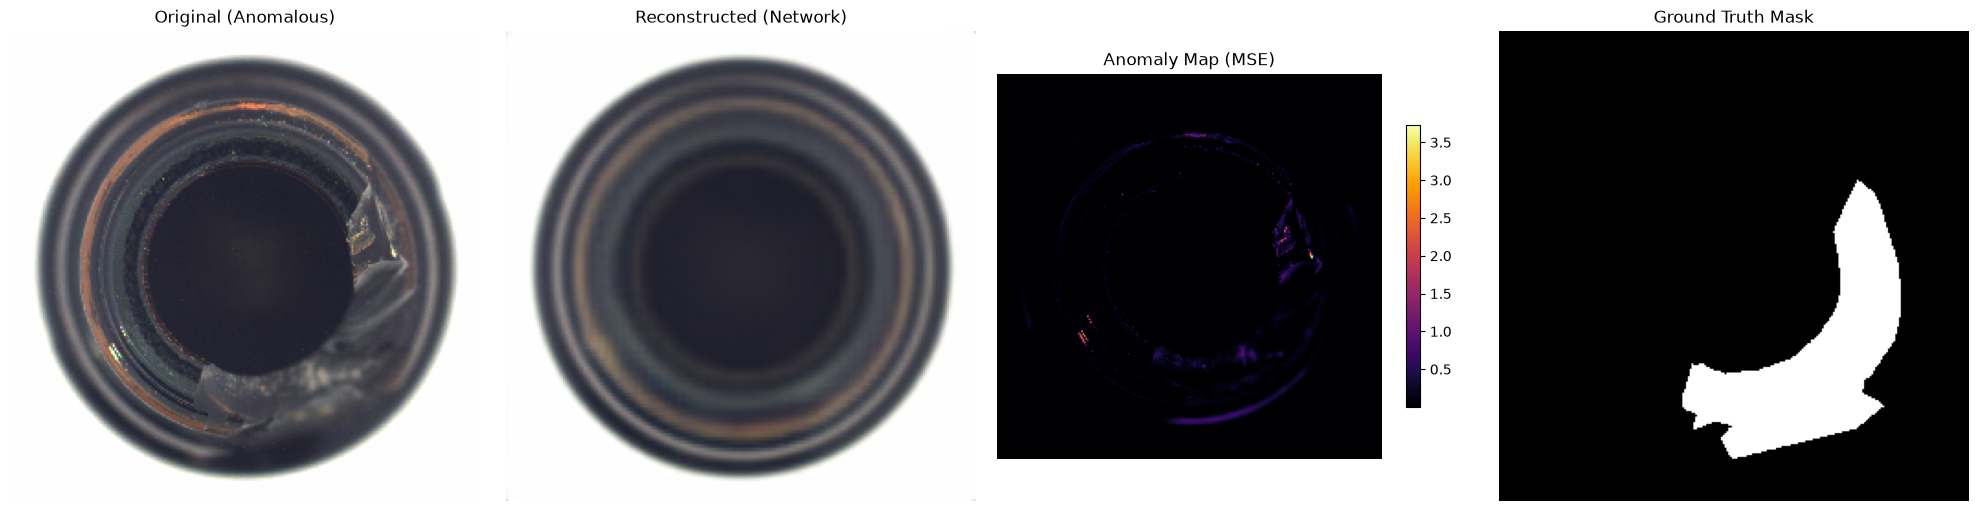

In [22]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].imshow(original_vis)
axes[0].set_title("Original (Anomalous)")
axes[0].axis('off')

axes[1].imshow(reconstructed_vis)
axes[1].set_title("Reconstructed (Network)")
axes[1].axis('off')

im = axes[2].imshow(anomaly_map, cmap='inferno')
axes[2].set_title("Anomaly Map (MSE)")
axes[2].axis('off')
fig.colorbar(im, ax=axes[2], shrink=0.6)

axes[3].imshow(ground_truth_mask, cmap='gray')
axes[3].set_title("Ground Truth Mask")
axes[3].axis('off')

plt.tight_layout()
plt.show()

In [28]:
from pathlib import Path
from sklearn.metrics import roc_auc_score, roc_curve

all_pixel_scores = []
all_pixel_labels = []
visuals_per_class = {}

with torch.no_grad():
    for images, masks, labels, paths in test_dataloader:
        images = images.to(DEVICE)
        reconstructions = model(images)
        anomaly_maps = torch.abs(images - reconstructions).mean(dim=1)

        anomaly_maps_np = anomaly_maps.cpu().numpy()
        masks_np = masks.squeeze(1).cpu().numpy()

        all_pixel_scores.extend(anomaly_maps_np.flatten())
        all_pixel_labels.extend(masks_np.flatten())

        for i, path in enumerate(paths):
            defect_type = Path(path).parent.name
            if defect_type not in visuals_per_class and defect_type != 'good':
                visuals_per_class[defect_type] = {
                    'original': images[i].cpu(),
                    'reconstruction': reconstructions[i].cpu(),
                    'anomaly_map': anomaly_maps[i].cpu(),
                    'mask': masks_np[i]
                }

all_pixel_scores = np.array(all_pixel_scores)
all_pixel_labels = np.array(all_pixel_labels).astype(int)

pixel_roc_auc = roc_auc_score(all_pixel_labels, all_pixel_scores)

fpr, tpr, thresholds = roc_curve(all_pixel_labels, all_pixel_scores)
optimal_idx = np.argmax(tpr - fpr)
optimal_threshold = thresholds[optimal_idx]

print(f"Pixel-level ROC AUC: {pixel_roc_auc:.4f}")
print(f"Optimal threshold: {optimal_threshold:.4f}")


d:\Unsupervised-Anomaly-Detection-Using-Autoencoder-Architecture\.venv\Lib\site-packages\torch\utils\data\dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Pixel-level ROC AUC: 0.8558
Optimal threshold: 0.0762


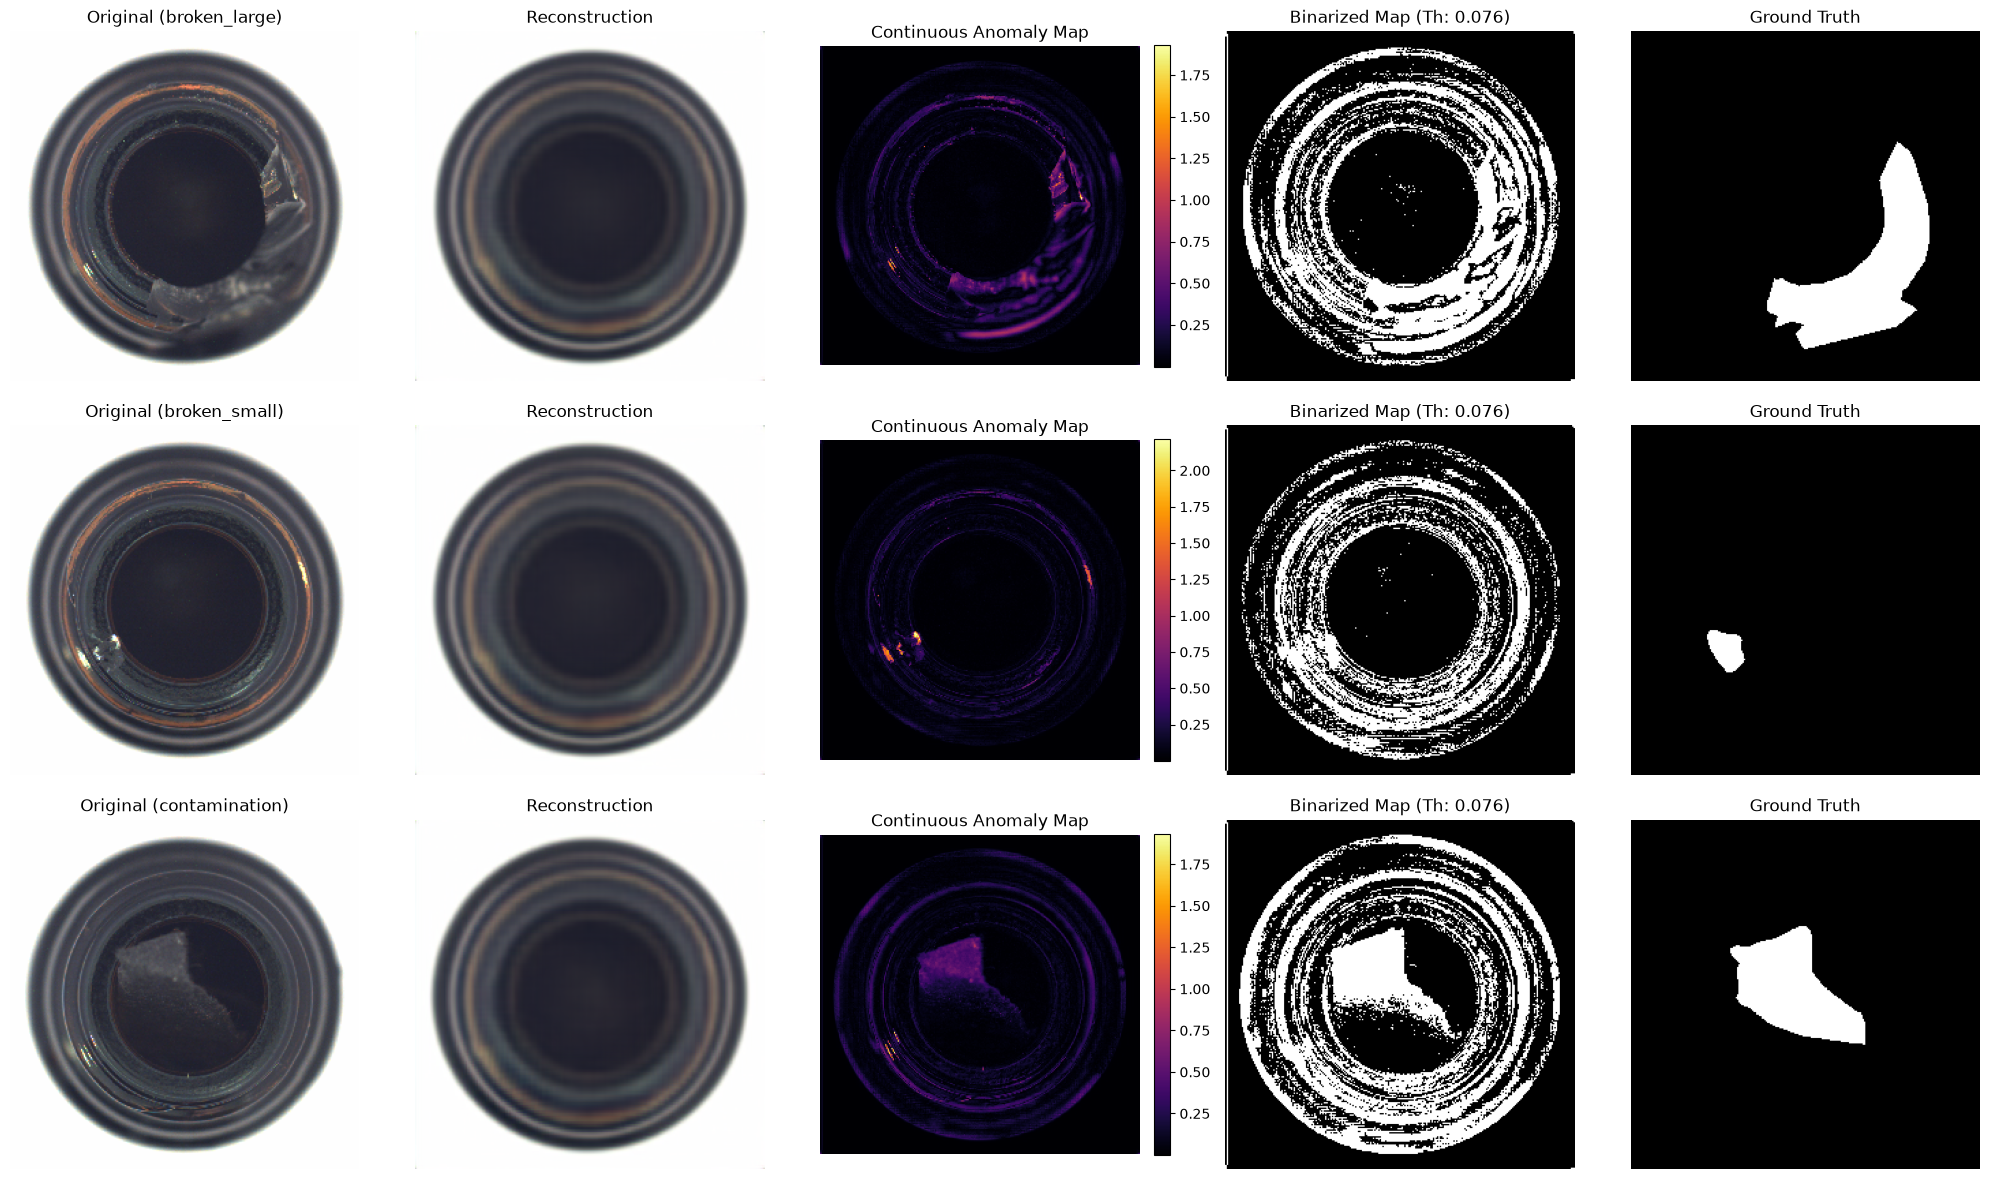

In [27]:
mean_np = np.array(BOTTLE_MEAN).reshape(3, 1, 1)
std_np = np.array(BOTTLE_STD).reshape(3, 1, 1)

num_classes = len(visuals_per_class)
fig, axes = plt.subplots(num_classes, 5, figsize=(20, 4 * num_classes))

for row_idx, (defect_type, data) in enumerate(visuals_per_class.items()):
    orig_img = np.clip((data['original'].numpy() * std_np + mean_np), 0, 1).transpose(1, 2, 0)
    recon_img = np.clip((data['reconstruction'].numpy() * std_np + mean_np), 0, 1).transpose(1, 2, 0)
    
    a_map = data['anomaly_map']
    mask = data['mask']
    
    binarized_map = (a_map.numpy() > optimal_threshold).astype(int)
    
    ax = axes[row_idx] if num_classes > 1 else axes
    
    ax[0].imshow(orig_img)
    ax[0].set_title(f"Original ({defect_type})")
    ax[0].axis('off')
    
    ax[1].imshow(recon_img)
    ax[1].set_title("Reconstruction")
    ax[1].axis('off')
    
    im = ax[2].imshow(a_map, cmap='inferno')
    ax[2].set_title("Continuous Anomaly Map")
    ax[2].axis('off')
    plt.colorbar(im, ax=ax[2], fraction=0.046, pad=0.04)
    
    ax[3].imshow(binarized_map, cmap='gray')
    ax[3].set_title(f"Binarized Map (Th: {optimal_threshold:.3f})")
    ax[3].axis('off')
    
    ax[4].imshow(mask, cmap='gray')
    ax[4].set_title("Ground Truth")
    ax[4].axis('off')

plt.tight_layout()
plt.show()